# UTS Praktikum Visi Komputer Kelompok 8
## Tema 8: Klasifikasi Bentuk dan Warna

## 1. Pendahuluan

*Suci Wiranda (2408107010077)*
*Aqila Ruqayyah (2408107010070)*
*Syifa Salsabila (2408107010018)*
*Shara Sitta Safiruddin (2408107010067)*


**Tugas:** dari foto potongan kertas berbagai bentuk dan warna, program memberi label tiap benda, misalnya `Segitiga - Merah`.
**Materi yang dipakai:** HSV dan `inRange` (pembanding), threshold (P3); `findContours`, `approxPolyDP`, `arcLength`, `convexHull`, `putText` (P4); blur Gaussian/median, morfologi, `HoughCircles` (P4); fungsi, dictionary, loop (P1); `imread`/`imwrite`, tampilan banyak gambar (P2).
**Library:** hanya `opencv-python`, `numpy`, `matplotlib` (plus modul standar Python seperti `csv`, `pathlib`). Tanpa deep learning.


## 2. Import dan fungsi bantu

Setiap tahap pipeline ditulis sebagai fungsi Python (P1). Berikut parameter dan alasannya pada bagian-bagian berikutnya.

In [206]:
import csv, glob, math, os, time
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

In [207]:
MAX_SISI = 1000                       # sisi terpanjang citra setelah resize
BENTUK = ["Segitiga", "Persegi", "Persegi panjang", "Lingkaran", "Bintang", "Love"]
WARNA  = ["Merah", "Kuning", "Hijau", "Biru", "Hitam", "Mint", "Ungu", "Pink", "Soft pink"]

### 2.1 Preprocessing
Membaca citra, resize (sisi terpanjang 1000 px), Gaussian blur, dan konversi ke Lab.

In [208]:
def muat_citra(path, max_sisi=MAX_SISI):
    """Baca citra (OpenCV sudah menerapkan orientasi EXIF) lalu resize dengan rasio tetap."""
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(path)
    h, w = img.shape[:2]
    s = min(1.0, max_sisi / max(h, w))
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)


def praproses(img):
    """Gaussian blur lalu konversi BGR -> Lab (jarak warna di Lab mendekati persepsi mata)."""
    blur = cv2.GaussianBlur(img, (5, 5), 0)
    lab = cv2.cvtColor(blur, cv2.COLOR_BGR2LAB).astype(np.float32)
    return blur, lab

### 2.2 Segmentasi (masking)
Mask dibuat dari **selisih terhadap latar lokal**, bukan dari rentang warna tetap.

In [209]:
def peta_skor(lab, latar):
    """Skor 'seberapa beda dari latar lokal'.
    kroma (a,b) -> objek berwarna ; 'gelap sekali' -> objek hitam.
    Bayangan hanya menurunkan L sedikit sehingga skornya kecil dan tidak ikut jadi objek."""
    d = lab - latar
    kroma = np.sqrt(d[:, :, 1] ** 2 + d[:, :, 2] ** 2)
    gelap = np.maximum(0, -d[:, :, 0] - 25)
    return np.maximum(kroma, gelap)


def estimasi_latar(lab, n_iter=4, sigma=35, thr=8):
    """Perkirakan warna latar tiap piksel (latar tidak rata: gradasi cahaya, lantai, bayangan).
    1) tebakan awal: median blur besar pada citra kecil (objek kecil terhapus)
    2) ulangi: objek yang sudah ketemu dikeluarkan, latar = rata-rata Gaussian piksel latar saja."""
    h, w = lab.shape[:2]
    kecil = cv2.resize(lab.astype(np.uint8), None, fx=0.125, fy=0.125, interpolation=cv2.INTER_AREA)
    latar = cv2.resize(cv2.medianBlur(kecil, 41), (w, h), interpolation=cv2.INTER_LINEAR).astype(np.float32)
    kern = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    for _ in range(n_iter):
        fg = cv2.dilate((peta_skor(lab, latar) > thr).astype(np.uint8), kern)
        bobot = (1 - fg).astype(np.float32)
        num = cv2.GaussianBlur(lab * bobot[:, :, None], (0, 0), sigma)
        den = cv2.GaussianBlur(bobot, (0, 0), sigma)[:, :, None]
        latar = np.where(den > 0.02, num / np.maximum(den, 1e-3), latar)
    return latar


def segmentasi(img, thr=8):
    """Mask objek = threshold pada peta skor, lalu opening untuk membuang garis tipis (nat lantai, tepi foto)."""
    blur, lab = praproses(img)
    latar = estimasi_latar(lab, thr=thr)
    skor = peta_skor(lab, latar)
    skor8 = np.clip(skor * 4, 0, 255).astype(np.uint8)
    _, mask = cv2.threshold(skor8, thr * 4, 255, cv2.THRESH_BINARY)
    k7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k7)
    return mask, skor, lab, latar


K5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))


def pisah_menempel(mask, img):
    """Pisahkan objek yang bersentuhan: marker = inti distance transform, lalu watershed."""
    hasil = np.zeros(mask.shape, np.int32)
    n, lbl, st, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blur = cv2.GaussianBlur(img, (5, 5), 0)
    nomor = 1
    for i in range(1, n):
        x, y, w, h, a = st[i]
        x0, y0 = max(0, x - 5), max(0, y - 5)
        x1, y1 = min(mask.shape[1], x + w + 5), min(mask.shape[0], y + h + 5)
        comp = (lbl[y0:y1, x0:x1] == i).astype(np.uint8)
        dt = cv2.distanceTransform(comp, cv2.DIST_L2, 5)
        inti = (dt > 0.62 * dt.max()).astype(np.uint8)
        nc, cl = cv2.connectedComponents(inti)
        besar = [k for k in range(1, nc) if (cl == k).sum() >= 40]
        if len(besar) >= 2:
            mk = np.zeros(comp.shape, np.int32)
            for j, k in enumerate(besar):
                mk[cl == k] = j + 2
            mk[comp == 0] = 1
            ws = cv2.watershed(blur[y0:y1, x0:x1].copy(), mk)
            for j in range(len(besar)):
                bagian = cv2.morphologyEx((ws == j + 2).astype(np.uint8), cv2.MORPH_OPEN, K5)
                hasil[y0:y1, x0:x1][bagian > 0] = nomor
                nomor += 1
        else:
            hasil[y0:y1, x0:x1][comp > 0] = nomor
            nomor += 1
    return hasil, nomor - 1

### 2.3 Deteksi kontur
`findContours` pada mask, lalu membuang kontur yang bukan potongan kertas (terlalu kecil, terlalu besar, atau memanjang di tepi foto).

In [210]:
def luas_solid(c):
    a = cv2.contourArea(c)
    ha = cv2.contourArea(cv2.convexHull(c))
    return a, (a / ha if ha > 0 else 0)


def deteksi(img):
    """Mask -> pisah objek menempel -> findContours -> buang noise (kecil, besar, menempel tepi foto)."""
    mask, skor, lab, latar = segmentasi(img)
    H, W = mask.shape
    total = H * W
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, K5)
    label, n = pisah_menempel(mask, img)
    kontur = []
    for k in range(1, n + 1):
        cs, _ = cv2.findContours((label == k).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not cs:
            continue
        c = max(cs, key=cv2.contourArea)
        a, sol = luas_solid(c)
        if a < total * 0.0009 or a > total * 0.12:
            continue                                   # terlalu kecil (noise/pantulan) / terlalu besar (bukan objek)
        x, y, w, h = cv2.boundingRect(c)
        nempel = x <= 2 or y <= 2 or x + w >= W - 2 or y + h >= H - 2
        if nempel:
            (_, _), (rw, rh), _ = cv2.minAreaRect(c)
            asp = max(rw, rh) / max(1e-6, min(rw, rh))
            # objek yang terpotong tepi foto tetap boleh asal padat (cembung, tidak memanjang, tidak raksasa);
            # tepi meja, keyboard, tangan, dan bingkai hitam foto biasanya memanjang/tidak padat/besar.
            if not (sol > 0.9 and asp < 3 and a < total * 0.04):
                continue
        if sol < 0.45:
            continue
        kontur.append(c)
    return mask, kontur, lab, latar

### 2.4 Klasifikasi bentuk
Materi wajib: `approxPolyDP`, `arcLength`, `convexHull`, rasio sisi. Persegi vs persegi panjang memakai rasio sisi segiempat hasil `approxPolyDP`; perbandingan `boundingRect` bisa salah pada objek yang diputar, jadi dipakai sisi-sisi poligon.

Aturan:
1. banyak cekungan dalam (convexity defects ≥3) dan solidity <0,80 → **Bintang**
2. cembung penuh dan menyerupai lingkaran/elips → **Lingkaran** (elips karena foto miring)
3. 3 titik pada epsilon 0,04 → **Segitiga**
4. 4 titik → **Persegi** (rasio sisi <1,4) atau **Persegi panjang**
5. cembung tapi bergelombang (≥6 titik) dengan satu lekukan → **Love**

In [211]:
def fitur_bentuk(c, eps_halus=0.02, eps_kasar=0.04):
    a = cv2.contourArea(c)
    per = cv2.arcLength(c, True)
    hull = cv2.convexHull(c)
    sol = a / max(cv2.contourArea(hull), 1e-6)
    circ = 4 * np.pi * a / max(per * per, 1e-6)
    n_halus = len(cv2.approxPolyDP(c, eps_halus * per, True))
    n_kasar = len(cv2.approxPolyDP(c, eps_kasar * per, True))
    n_cekung = 0
    
    try:
        idx = cv2.convexHull(c, returnPoints=False)
        df = cv2.convexityDefects(c, idx)
        if df is not None:
            # Mengamankan dimensi array tanpa peduli versi OpenCV
            df_aman = df.reshape(-1, 4)
            n_cekung = int(sum(1 for d in df_aman if d[3] / 256.0 > 0.04 * np.sqrt(a)))
    except cv2.error:
        pass
        
    return dict(luas=a, keliling=per, solid=sol, circ=circ, n_halus=n_halus, n_kasar=n_kasar, n_cekung=n_cekung)


def iou_elips(c):
    """Seberapa mirip kontur dengan elips terbaik (lingkaran yang difoto miring = elips)."""
    if len(c) < 5:
        return 0.0
    (cx, cy), (MA, ma), ang = cv2.fitEllipse(c)
    x, y, w, h = cv2.boundingRect(c)
    pad = 10
    A = np.zeros((h + 2 * pad, w + 2 * pad), np.uint8)
    B = A.copy()
    cv2.drawContours(A, [c - [x - pad, y - pad]], -1, 255, -1)
    cv2.ellipse(B, ((cx - x + pad, cy - y + pad), (MA, ma), ang), 255, -1)
    return np.logical_and(A > 0, B > 0).sum() / max(np.logical_or(A > 0, B > 0).sum(), 1)


def rasio_sisi(c):
    """Rasio sisi segiempat. Dipakai 4 titik hasil approxPolyDP (rata-rata sisi berhadapan) agar
    tahan terhadap rotasi dan sudut miring; cadangan: minAreaRect."""
    per = cv2.arcLength(c, True)
    q = cv2.approxPolyDP(c, 0.04 * per, True)
    if len(q) != 4:
        (_, _), (rw, rh), _ = cv2.minAreaRect(c)
        return max(rw, rh) / max(1e-6, min(rw, rh))
    p = q[:, 0, :].astype(np.float32)
    s = [np.linalg.norm(p[i] - p[(i + 1) % 4]) for i in range(4)]
    a, b = (s[0] + s[2]) / 2, (s[1] + s[3]) / 2
    return max(a, b) / max(1e-6, min(a, b))


def klasifikasi_bentuk(c, eps_halus=0.02, eps_kasar=0.04, f=None):
    f = f or fitur_bentuk(c, eps_halus, eps_kasar)
    n2, n4 = f["n_halus"], f["n_kasar"]
    if f["solid"] < 0.80 and f["n_cekung"] >= 3:                 # banyak cekungan dalam -> bintang
        return "Bintang"
    if f["solid"] > 0.95 and n2 >= 6 and (f["circ"] > 0.85 or iou_elips(c) > 0.93):
        return "Lingkaran"
    if n4 == 3 and n2 <= 5 and f["solid"] > 0.88:
        return "Segitiga"
    if n2 <= 5 and n4 == 4 and f["solid"] > 0.92:
        return "Persegi" if rasio_sisi(c) < 1.4 else "Persegi panjang"
    if f["solid"] > 0.88 and n2 >= 6:                            # cembung, ada 1 lekukan -> love
        return "Love"
    if n4 == 3:
        return "Segitiga"
    if n4 == 4:
        return "Persegi" if rasio_sisi(c) < 1.4 else "Persegi panjang"
    return "Love"

### 2.5 Klasifikasi warna
Warna objek = median (ΔL, Δa, Δb) bagian dalam objek dikurangi latar lokal. Sudut (a,b) menentukan jenis warna, kekuatan (kroma) membedakan warna pekat dari pastel.

In [212]:
def mask_dalam(shape, c, erode=9):
    m = np.zeros(shape[:2], np.uint8)
    cv2.drawContours(m, [c], -1, 255, -1)
    er = cv2.erode(m, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (erode, erode)))
    return er if er.sum() >= 255 * 30 else m          # buang piksel tepi (campur dengan latar)


def selisih_lab(lab, latar, c):
    """Median (dL, da, db) bagian dalam objek relatif terhadap latar lokal => kebal terhadap
    warna lampu dan bayangan karena latar ikut berubah bersama objek."""
    er = mask_dalam(lab.shape, c)
    return np.median((lab - latar)[er > 0], axis=0)


def klasifikasi_warna(d):
    dL, da, db = [float(x) for x in d]
    sudut = np.degrees(np.arctan2(db, da))            # arah warna (hue) di bidang a-b
    kroma = np.hypot(da, db)                          # kekuatan warna
    if dL < -55 and kroma < 16:
        return "Hitam"
    if kroma < 7:
        return "Abu-abu"
    if -140 <= sudut <= -85:
        return "Biru"
    if 80 <= sudut <= 112:
        return "Kuning"
    if -85 < sudut < -33:
        return "Ungu"
    if -33 <= sudut <= 45:
        if kroma > 35:
            return "Merah" if sudut > 5 else "Pink"
        return "Soft pink"
    if sudut > 112 or sudut < -140:
        return "Mint" if kroma < 25 else "Hijau"
    return "Oranye"

### 2.6 Pipeline lengkap dan penggambaran label
`analisis_citra()` menggabungkan semua tahap. Label ditulis dengan `putText` (contoh: `Segitiga - Merah`).

In [213]:
def klasifikasi_objek(kontur, lab, latar, eps_halus=0.02, eps_kasar=0.04):
    """Beri label (bentuk, warna) pada setiap kontur dan buang objek yang tidak masuk akal."""
    objek = []
    for c in sorted(kontur, key=lambda k: (cv2.boundingRect(k)[1] // 60, cv2.boundingRect(k)[0])):
        f = fitur_bentuk(c, eps_halus, eps_kasar)
        bentuk = klasifikasi_bentuk(c, eps_halus, eps_kasar, f)
        warna = klasifikasi_warna(selisih_lab(lab, latar, c))
        if warna == "Abu-abu":
            continue                                   # tidak berwarna = bukan potongan kertas
        if warna == "Hitam" and bentuk != "Lingkaran":
            continue                                   # benda hitam yang valid hanya lingkaran
        objek.append(dict(kontur=c, bentuk=bentuk, warna=warna, fitur=f))
    return objek


def analisis_citra(img, eps_halus=0.02, eps_kasar=0.04):
    mask, kontur, lab, latar = deteksi(img)
    objek = klasifikasi_objek(kontur, lab, latar, eps_halus, eps_kasar)
    return dict(mask=mask, kontur=kontur, objek=objek, lab=lab, latar=latar)


def gambar_hasil(img, objek):
    out = img.copy()
    for o in objek:
        c = o["kontur"]
        cv2.drawContours(out, [c], -1, (0, 255, 0), 2)
        cv2.drawContours(out, [cv2.convexHull(c)], -1, (255, 0, 255), 1)
        x, y, w, h = cv2.boundingRect(c)
        teks = f'{o["bentuk"]} - {o["warna"]}'
        pos = (x, max(y - 6, 14))
        cv2.putText(out, teks, pos, cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 3, cv2.LINE_AA)
        cv2.putText(out, teks, pos, cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
    return out

### 2.7 Ground truth dan pencocokan
Pencocokan sebagai multiset karena ground truth tidak menyertakan posisi objek.

In [214]:
def baca_gt(path):
    with open(path, encoding="utf-8-sig", newline="") as f:
        return [{k.strip(): (v or "").strip() for k, v in r.items()} for r in csv.DictReader(f)]


NAMA_BENTUK = [("persegi panjang", "Persegi panjang"), ("persegi", "Persegi"), ("segitiga", "Segitiga"),
               ("lingkaran", "Lingkaran"), ("bintang", "Bintang"), ("love", "Love")]
NAMA_WARNA = {"soft pink": "Soft pink", "mint": "Mint", "ungu": "Ungu", "biru": "Biru", "merah": "Merah",
              "kuning": "Kuning", "hijau": "Hijau", "hitam": "Hitam", "pink": "Pink"}


def parse_keterangan(teks):
    hasil = []
    for tok in teks.split(","):
        t = tok.strip().lower()
        for kunci, nama in NAMA_BENTUK:
            if t.startswith(kunci):
                hasil.append((nama, NAMA_WARNA[t[len(kunci):].strip()]))
                break
    return hasil


def cocokkan(pred, gt):
    """Perbandingan multiset (urutan objek tidak penting)."""
    lab_ok = sum((Counter(pred) & Counter(gt)).values())
    bentuk_ok = sum((Counter([p[0] for p in pred]) & Counter([g[0] for g in gt])).values())
    warna_ok = sum((Counter([p[1] for p in pred]) & Counter([g[1] for g in gt])).values())
    return lab_ok, bentuk_ok, warna_ok

### 2.8 Proses untuk Objek Besar

In [215]:
#objek besar
RENTANG_HSV = {
    "Merah":     [((0, 100, 60), (6, 255, 255)), ((176, 100, 60), (179, 255, 255))],
    "Pink":      [((158, 100, 60), (175, 255, 255))],
    "Soft pink": [((159, 25, 150), (179, 99, 255)), ((0, 25, 150), (8, 99, 255))],
    "Ungu":      [((120, 20, 40), (158, 120, 255))],
    "Kuning":    [((18, 100, 60), (35, 255, 255))],
    "Hijau":     [((36, 85, 20), (85, 255, 200))],
    "Mint":      [((30, 10, 120), (60, 84, 255))],
    "Biru":      [((86, 100, 40), (130, 255, 255))],
    "Hitam":     [((0, 0, 0), (179, 110, 74))],
}


def warna_hsv_inrange(hsv, c):
    """Warna = rentang HSV dengan cakupan terbesar (cv2.inRange) di dalam objek."""
    er = mask_dalam(hsv.shape, c)
    total = max((er > 0).sum(), 1)
    skor = {}
    for nama, daftar in RENTANG_HSV.items():
        m = np.zeros(er.shape, np.uint8)
        for bawah, atas in daftar:
            m |= cv2.inRange(hsv, np.array(bawah), np.array(atas))
        skor[nama] = ((m > 0) & (er > 0)).sum() / total
    return max(skor, key=skor.get)


def cari_seed(img, min_luas=0.001, maks=4):
    """Bagian yang sangat jenuh (S>=140) dan cerah, diurutkan dari yang terbesar."""
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (7, 7), 0), cv2.COLOR_BGR2HSV)
    seed = cv2.inRange(hsv, np.array([0, 140, 140]), np.array([179, 255, 255]))
    seed = cv2.morphologyEx(seed, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    n, lbl, st, _ = cv2.connectedComponentsWithStats(seed)
    ids = [i for i in np.argsort(-st[1:, 4]) + 1 if st[i, 4] >= min_luas * seed.size][:maks]
    return ids, lbl, hsv


def analisis_objek_besar(img, min_luas_objek=0.20):
    """Mode objek besar (sticky note memenuhi sepertiga foto, latar ramai).
    Region growing: seed = bagian paling jenuh; wilayah = piksel yang warnanya (Lab) dekat warna seed.
    Dianggap objek besar bila luas > 20% foto dan padat (solidity > 0,9)."""
    ids, lbl, hsv = cari_seed(img)
    blur = cv2.GaussianBlur(img, (7, 7), 0)
    lab = cv2.cvtColor(blur, cv2.COLOR_BGR2LAB).astype(np.float32)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    mask_total = np.zeros(img.shape[:2], np.uint8)
    objek = []
    for i in ids:
        titik = np.argwhere(lbl == i)[0][::-1]                         # satu piksel seed (x, y)
        med = np.median(lab[lbl == i], axis=0)
        d = np.sqrt((lab[:, :, 1] - med[1]) ** 2 + (lab[:, :, 2] - med[2]) ** 2 + (0.5 * (lab[:, :, 0] - med[0])) ** 2)
        reg = (d < 30).astype(np.uint8) * 255
        reg = cv2.morphologyEx(reg, cv2.MORPH_CLOSE, k, iterations=2)  # tutup lubang tulisan tangan
        reg = cv2.morphologyEx(reg, cv2.MORPH_OPEN, k)
        cs, _ = cv2.findContours(reg, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cs = [c for c in cs if cv2.pointPolygonTest(c, (float(titik[0]), float(titik[1])), False) >= 0]
        if not cs:
            continue
        c = max(cs, key=cv2.contourArea)
        if cv2.contourArea(c) < min_luas_objek * reg.size or luas_solid(c)[1] < 0.9:
            continue
        cv2.drawContours(mask_total, [c], -1, 255, -1)
        f = fitur_bentuk(c)
        objek.append(dict(kontur=c, bentuk=klasifikasi_bentuk(c, f=f), warna=warna_hsv_inrange(hsv, c), fitur=f))
    return dict(mask=mask_total, kontur=[o["kontur"] for o in objek], objek=objek, mode="besar")


def analisis_otomatis(img):
    """Ada objek yang menutupi >20% foto -> mode besar; selain itu pipeline normal."""
    hasil = analisis_objek_besar(img)
    if hasil["objek"]:
        return hasil
    hasil = analisis_citra(img)
    hasil["mode"] = "normal"
    return hasil

## 3. Memuat dataset

Semua foto dicari secara otomatis dari folder tempat notebook ini berada,
jadi notebook bisa dijalankan ulang di komputer lain selama folder dataset dan file ground truth ada di samping notebook.
Folder `output/` dibuat otomatis untuk menyimpan hasil.

Ground truth : ground_truth.csv - 27 baris
Foto ditemukan: 70
Ada di GT tetapi fotonya tidak ada: tidak ada
  ideal  : 10 foto
  cahaya : 4 foto
  sudut  : 6 foto
  sulit  : 7 foto


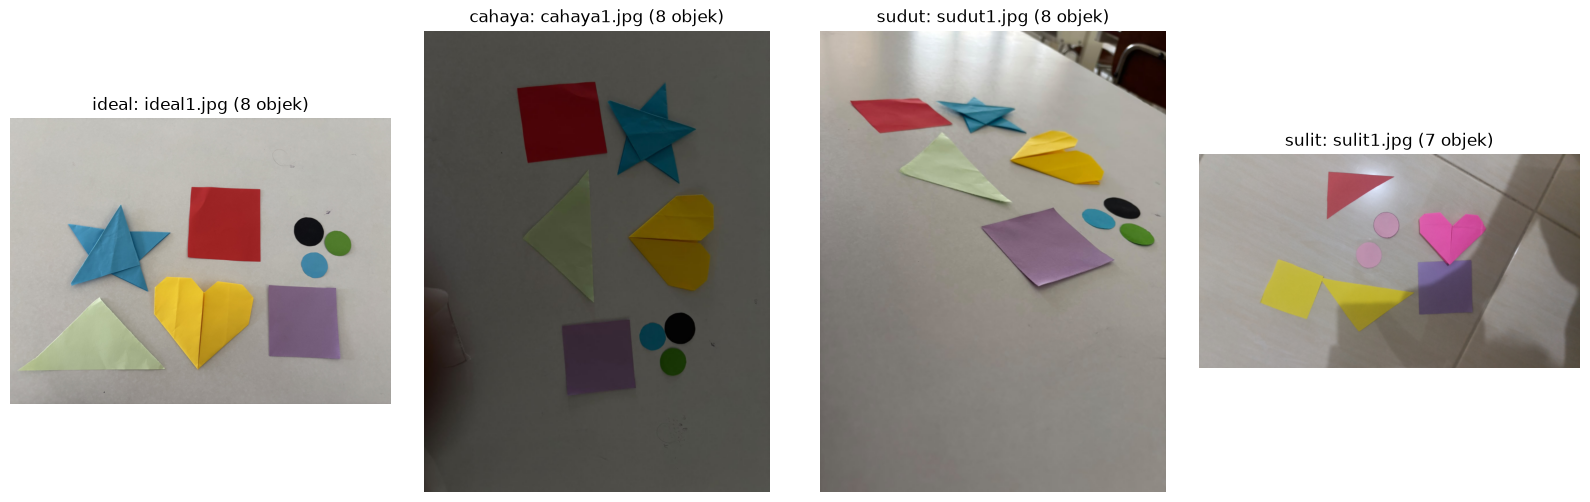

In [216]:
BASE = Path(".")
OUT = BASE / "output"
OUT.mkdir(exist_ok=True)

# mencari ground truth
GT_PATH = next(p for p in sorted(BASE.rglob("*.csv")) if "ground" in p.name.lower() and OUT not in p.parents)
GT = baca_gt(GT_PATH)

# semua foto (kecuali yang ada di folder output)
FOTO = {p.name: p for p in BASE.rglob("*.jpg") if OUT not in p.parents}

hilang = [r["file"] for r in GT if r["file"] not in FOTO]
print("Ground truth :", GT_PATH.name, "-", len(GT), "baris")
print("Foto ditemukan:", len(FOTO))
print("Ada di GT tetapi fotonya tidak ada:", hilang if hilang else "tidak ada")

KONDISI = ["ideal", "cahaya", "sudut", "sulit"]
for k in KONDISI:
    print(f"  {k:7s}: {sum(1 for r in GT if r['kondisi'] == k)} foto")

# tampilkan 1 citra per kondisi dalam satu figure (P2)
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, k in zip(axes, KONDISI):
    r = next(r for r in GT if r["kondisi"] == k)
    ax.imshow(cv2.cvtColor(muat_citra(FOTO[r["file"]]), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{k}: {r['file']} ({r['jumlah_objek']} objek)")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Pipeline langkah demi langkah

Satu fungsi `tampil_langkah()` menampilkan hasil antara setiap tahap. Alasan pemilihan metode:

| Tahap | Metode | Alasan |
|---|---|---|
| Praproses | GaussianBlur 5x5, BGR→Lab | menghaluskan noise kamera; Lab dipilih karena jarak warna di Lab mendekati persepsi manusia dan memisahkan kecerahan (L) dari warna (a, b) |
| Estimasi latar | median blur pada citra 1/8 + rata-rata Gaussian berulang (4 iterasi) | latar tidak rata (gradasi cahaya, lantai, bayangan). Objek dikeluarkan dulu agar tidak "mengotori" estimasi latar |
| Peta skor | kroma (a,b) terhadap latar, atau gelap sekali | objek kertas berbeda **warna** dari latar, sedangkan bayangan hanya beda **kecerahan**, jadi bayangan tidak ikut terdeteksi |
| Threshold | `cv2.threshold` pada skor (ambang 8) | skor 8 di Lab setara beda warna yang mulai terlihat; kertas pastel (soft pink, mint) skornya 12–30 sehingga masih lolos |
| Morfologi | opening 7x7 lalu 5x5 | membuang garis tipis (nat lantai, tepi meja) tanpa merusak objek (terkecil sekitar 40 px) |
| Pisah objek menempel | distance transform + watershed | potongan kertas yang bersentuhan jadi satu komponen; marker dari inti distance transform memisahkannya |
| Kontur | `findContours` (RETR_EXTERNAL) + filter luas/tepi | membuang noise, bayangan besar, tangan, dan tepi foto |
| Bentuk | `approxPolyDP` + `arcLength`, `convexHull`, solidity, convexity defects, kecocokan elips | lihat bagian 2: aturan dibuat dari jumlah titik sudut dan ciri kecekungan |
| Warna | sudut dan kekuatan warna (a,b) objek relatif latar | tidak bergantung pada warna lampu dan bayangan |

In [217]:
def tampil_langkah(nama):
    img = muat_citra(FOTO[nama])
    blur, lab = praproses(img)
    latar = estimasi_latar(lab)
    skor = peta_skor(lab, latar)
    mask, _, _, _ = segmentasi(img)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, K5)
    label, n = pisah_menempel(mask, img)
    hasil = analisis_citra(img)

    rng = np.random.RandomState(3)
    warna_acak = rng.randint(60, 255, (n + 1, 3)).astype(np.uint8)
    warna_acak[0] = 0
    peta_label = warna_acak[label]

    kontur_img = img.copy()
    for o in hasil["objek"]:
        cv2.drawContours(kontur_img, [o["kontur"]], -1, (0, 255, 0), 2)
        cv2.drawContours(kontur_img, [cv2.convexHull(o["kontur"])], -1, (255, 0, 255), 1)

    rgb = lambda x: cv2.cvtColor(x, cv2.COLOR_BGR2RGB)
    panel = [
        (rgb(img), "1. Asli", None),
        (rgb(blur), "2. Gaussian blur 5x5", None),
        (rgb(cv2.cvtColor(latar.astype(np.uint8), cv2.COLOR_LAB2BGR)), "3. Latar terestimasi", None),
        (np.clip(skor, 0, 40), "4. Skor beda-dari-latar", "magma"),
        (mask, "5. Threshold + opening", "gray"),
        (rgb(peta_label), f"6. Watershed: {n} komponen", None),
        (rgb(kontur_img), "7. Kontur (hijau) + convex hull (ungu)", None),
        (rgb(gambar_hasil(img, hasil["objek"])), f"8. Hasil: {len(hasil['objek'])} objek", None),
    ]
    fig, axes = plt.subplots(2, 4, figsize=(18, 11))
    for ax, (im, judul, cmap) in zip(axes.ravel(), panel):
        ax.imshow(im, cmap=cmap)
        ax.set_title(judul, fontsize=11)
        ax.axis("off")
    fig.suptitle(nama, fontsize=14)
    plt.tight_layout()
    plt.show()



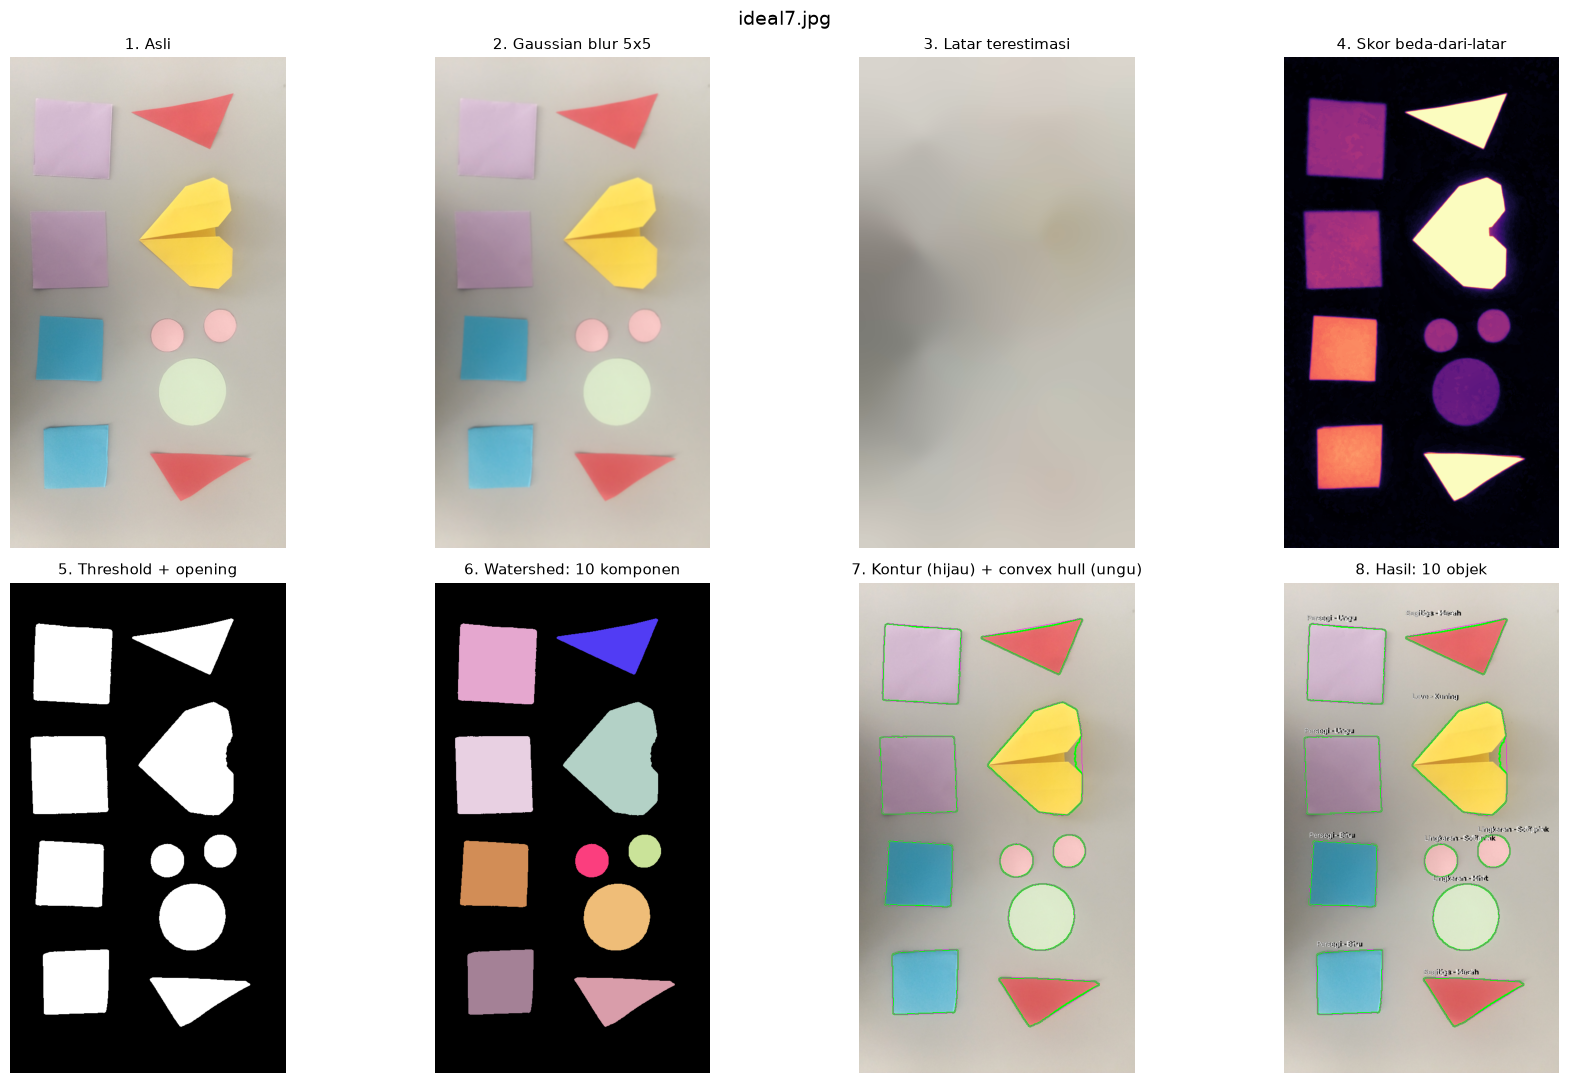

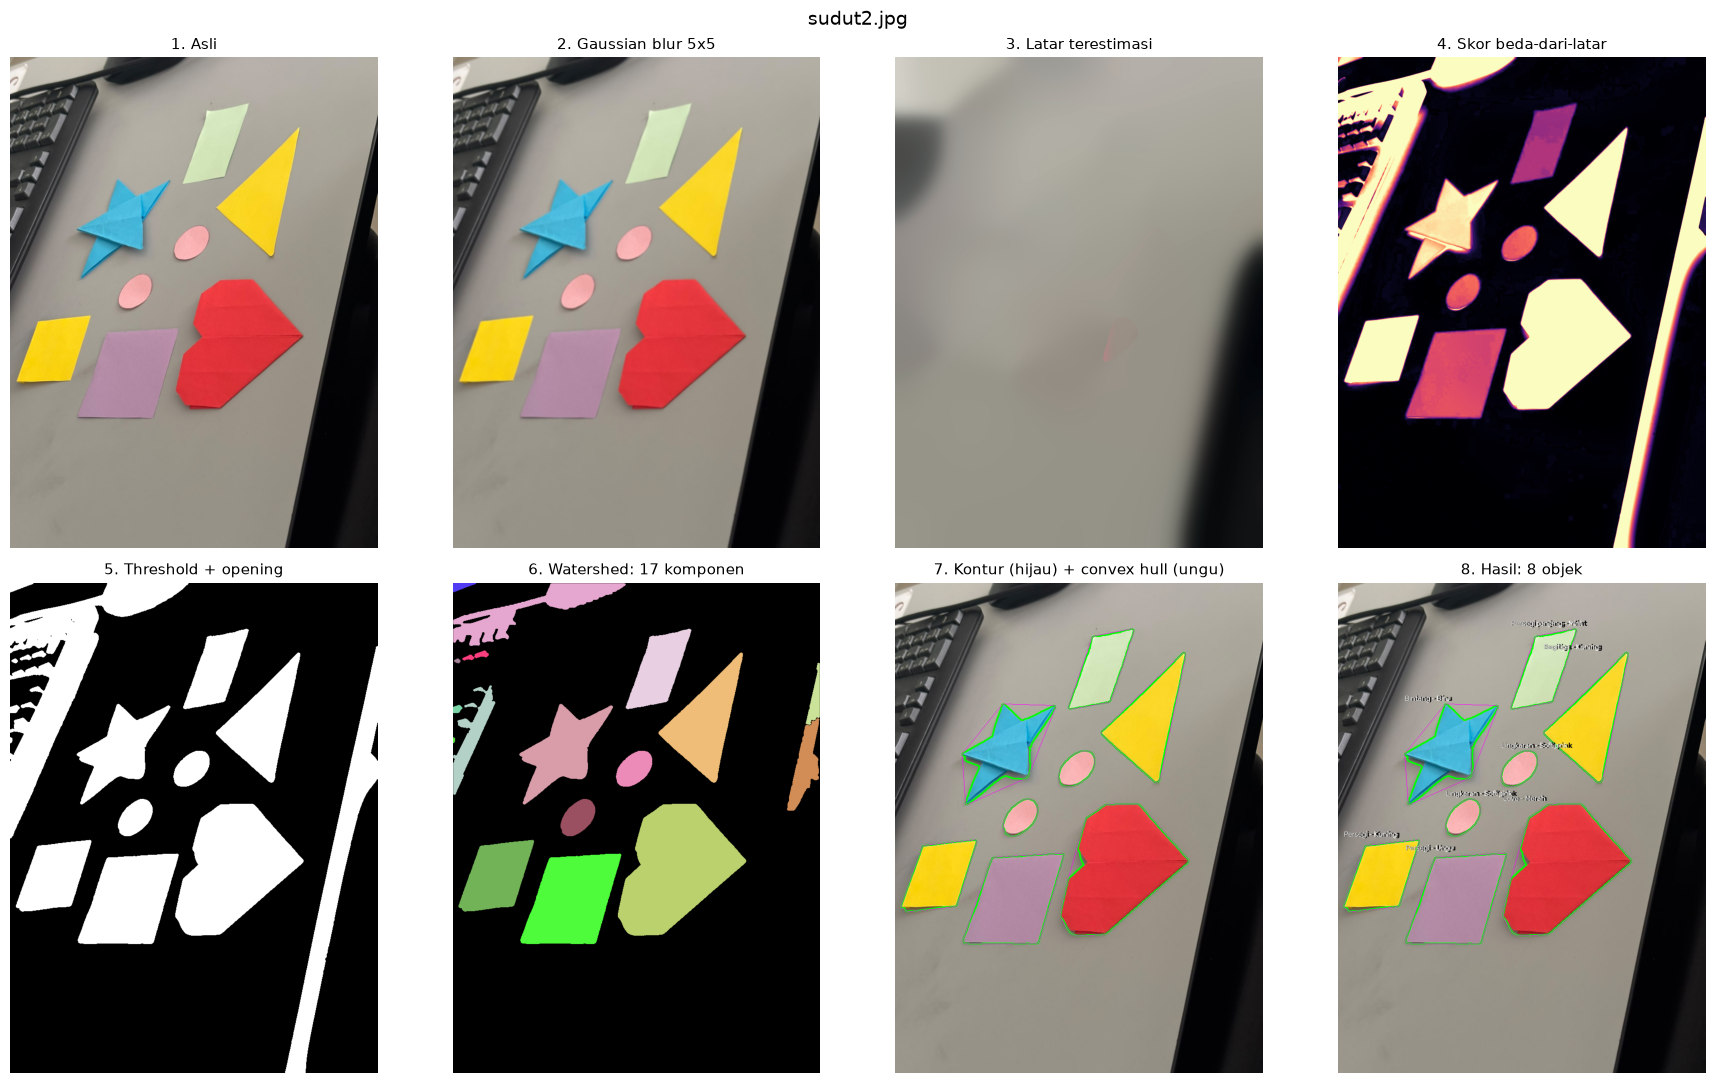

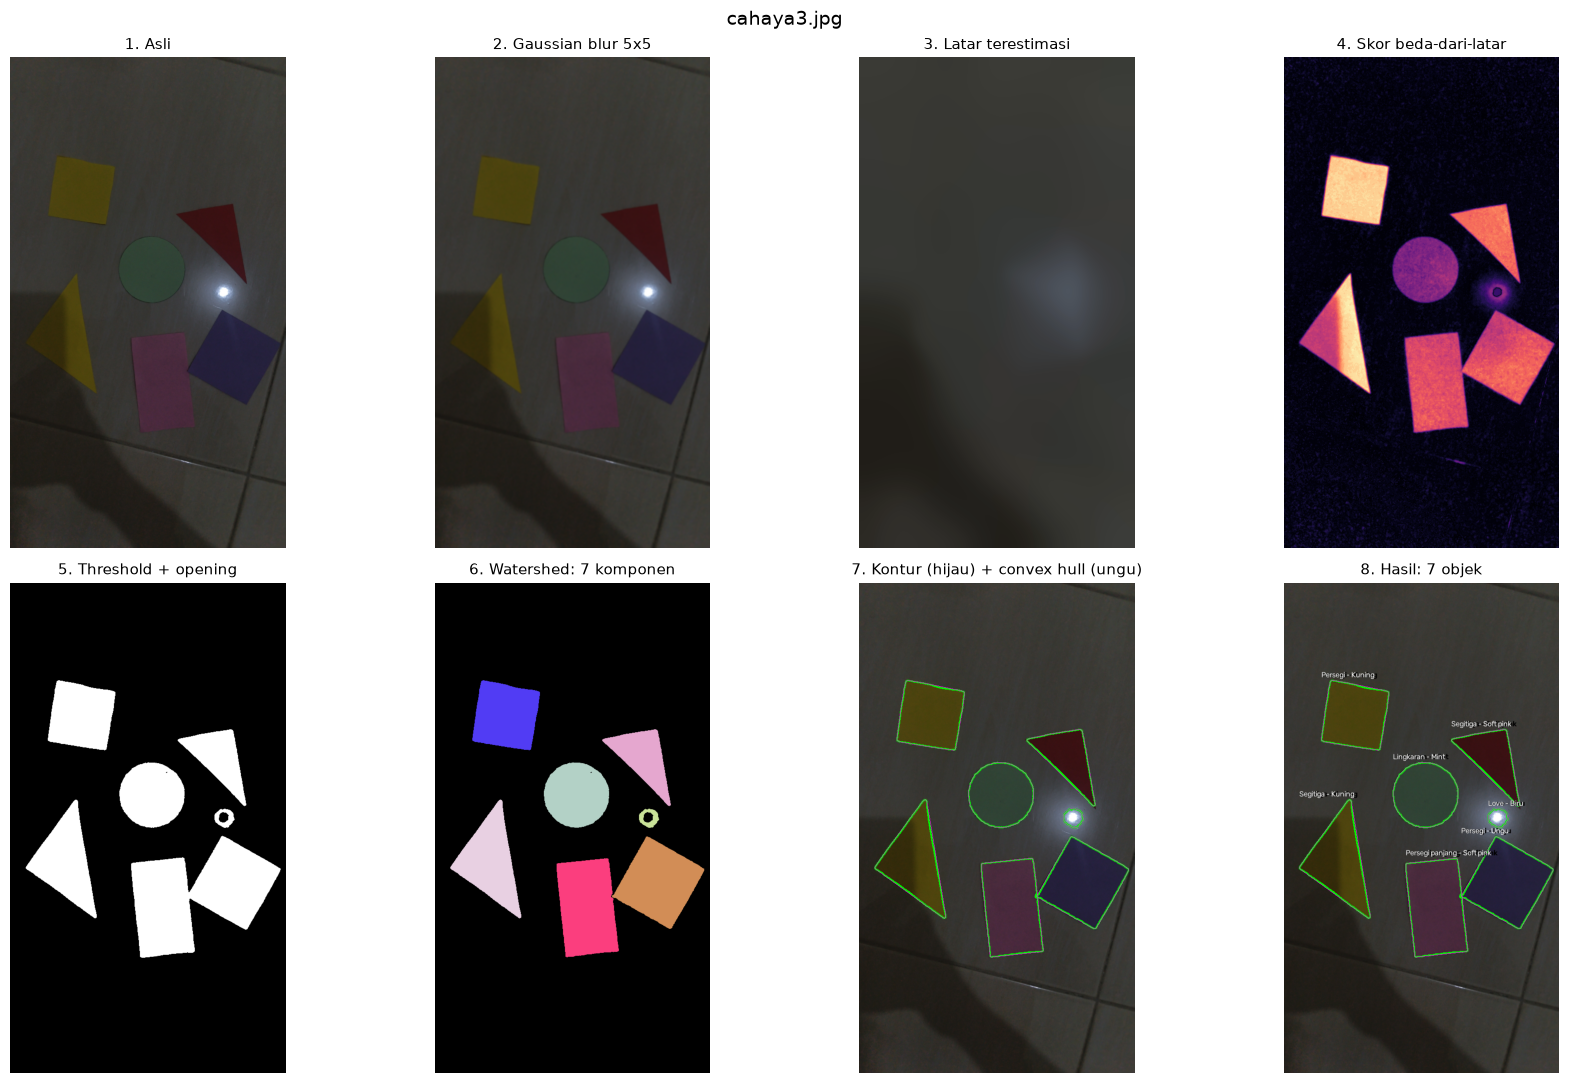

In [218]:
tampil_langkah("ideal7.jpg")      # kondisi ideal (ada objek pastel)
tampil_langkah("sudut2.jpg")      # foto miring + keyboard di latar
tampil_langkah("cahaya3.jpg")     # gelap + pantulan lampu

### Kenapa bukan `inRange` HSV langsung?

Versi awal memakai `inRange` HSV dengan rentang warna tetap. Cara itu gagal karena (1) kertas pastel (soft pink, mint, ungu muda)
saturasinya hampir sama dengan latar abu-krem sehingga hilang dari mask, (2) latar berwarna/bergradasi ikut masuk mask,
dan (3) hue bergeser saat lampu berubah. Pada bagian eksperimen (bagian 6) kedua cara dibandingkan secara kuantitatif.
`inRange` HSV tetap dipakai sebagai pembanding.

## 5. Evaluasi seluruh dataset

Pipeline dijalankan ke semua foto lalu dibandingkan dengan ground truth. Karena ground truth berisi daftar objek (bentuk + warna)
tanpa posisi, pencocokan dilakukan sebagai **multiset**: pasangan (bentuk, warna) yang sama dihitung satu per satu.

- **Akurasi jumlah**: banyak foto dengan jumlah objek prediksi = jumlah di ground truth.
- **Akurasi label** = pasangan (bentuk, warna) yang cocok ÷ max(jumlah GT, jumlah prediksi). Objek yang terlewat dan objek palsu sama-sama menurunkan nilai.
- **Akurasi bentuk / warna**: sama, tetapi hanya memeriksa bentuk saja atau warna saja.

In [219]:
t0 = time.time()
CACHE = {}      # simpan hasil deteksi agar eksperimen berikutnya tidak mengulang segmentasi
HASIL = []
for r in GT:
    img = muat_citra(FOTO[r["file"]])
    a = analisis_citra(img)
    CACHE[r["file"]] = (img, a)
    pred = [(o["bentuk"], o["warna"]) for o in a["objek"]]
    gt = parse_keterangan(r["keterangan"])
    lab_ok, bentuk_ok, warna_ok = cocokkan(pred, gt)
    HASIL.append(dict(file=r["file"], kondisi=r["kondisi"], n_gt=len(gt), n_pred=len(pred), pred=pred, gt=gt,
                      lab_ok=lab_ok, bentuk_ok=bentuk_ok, warna_ok=warna_ok, penyebut=max(len(gt), len(pred))))
    cv2.imwrite(str(OUT / f"hasil_{r['file']}"), gambar_hasil(img, a["objek"]))
print(f"Selesai {len(HASIL)} foto dalam {time.time() - t0:.0f} detik. Citra hasil disimpan di folder output/")

print()
print(f"{'file':12s}{'kondisi':8s}{'GT':>4s}{'pred':>6s}{'label':>7s}{'bentuk':>8s}{'warna':>7s}   {'akurasi':>7s}")
print("-" * 64)
for h in HASIL:
    print(f"{h['file']:12s}{h['kondisi']:8s}{h['n_gt']:4d}{h['n_pred']:6d}{h['lab_ok']:7d}{h['bentuk_ok']:8d}{h['warna_ok']:7d}   {100*h['lab_ok']/h['penyebut']:6.0f}%")

Selesai 27 foto dalam 34 detik. Citra hasil disimpan di folder output/

file        kondisi   GT  pred  label  bentuk  warna   akurasi
----------------------------------------------------------------
ideal1.jpg  ideal      8     8      8       8      8      100%
ideal2.jpg  ideal      7     7      7       7      7      100%
ideal3.jpg  ideal      5     5      5       5      5      100%
ideal4.jpg  ideal      8     8      8       8      8      100%
ideal5.jpg  ideal      9     9      9       9      9      100%
ideal6.jpg  ideal      8     8      8       8      8      100%
ideal7.jpg  ideal     10    10     10      10     10      100%
ideal8.jpg  ideal     11    11     11      11     11      100%
ideal9.jpg  ideal      8     8      8       8      8      100%
ideal10.jpg ideal      9     9      8       8      9       89%
sulit1.jpg  sulit      7     7      7       7      7      100%
sulit2.jpg  sulit      8     7      6       6      7       75%
sulit3.jpg  sulit      8     6      4       

kondisi   foto  jumlah tepat    label   bentuk    warna
-------------------------------------------------------
ideal       10         10/10    98.8%    98.8%   100.0%
cahaya       4           3/4    86.7%    93.3%    90.0%
sudut        6           4/6    84.4%    84.4%    93.3%
sulit        7           2/7    78.6%    82.1%    85.7%
TOTAL       27         19/27    88.8%    90.7%    93.5%


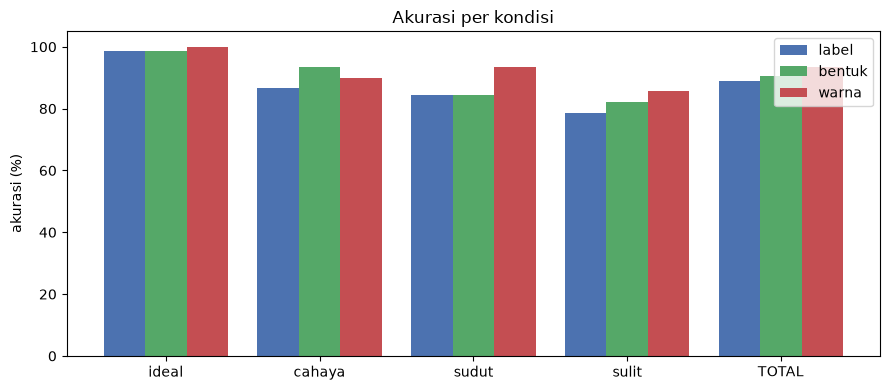

In [220]:
def ringkas(daftar):
    n = len(daftar)
    sama = sum(h["n_gt"] == h["n_pred"] for h in daftar)
    pen = sum(h["penyebut"] for h in daftar)
    return (n, sama, 100 * sum(h["lab_ok"] for h in daftar) / pen,
            100 * sum(h["bentuk_ok"] for h in daftar) / pen, 100 * sum(h["warna_ok"] for h in daftar) / pen)

print(f"{'kondisi':9s}{'foto':>5s}{'jumlah tepat':>14s}{'label':>9s}{'bentuk':>9s}{'warna':>9s}")
print("-" * 55)
RINGKAS = {}
for k in KONDISI + ["TOTAL"]:
    daftar = HASIL if k == "TOTAL" else [h for h in HASIL if h["kondisi"] == k]
    n, sama, a_lab, a_bentuk, a_warna = ringkas(daftar)
    RINGKAS[k] = (a_lab, a_bentuk, a_warna)
    print(f"{k:9s}{n:5d}{f'{sama}/{n}':>14s}{a_lab:8.1f}%{a_bentuk:8.1f}%{a_warna:8.1f}%")

x = np.arange(len(KONDISI) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
for i, (nama, c) in enumerate([("label", "#4c72b0"), ("bentuk", "#55a868"), ("warna", "#c44e52")]):
    ax.bar(x + (i - 1) * 0.27, [RINGKAS[k][i] for k in KONDISI + ["TOTAL"]], 0.27, label=nama, color=c)
ax.set_xticks(x); ax.set_xticklabels(KONDISI + ["TOTAL"]); ax.set_ylim(0, 105)
ax.set_ylabel("akurasi (%)"); ax.set_title("Akurasi per kondisi"); ax.legend()
plt.tight_layout(); plt.show()

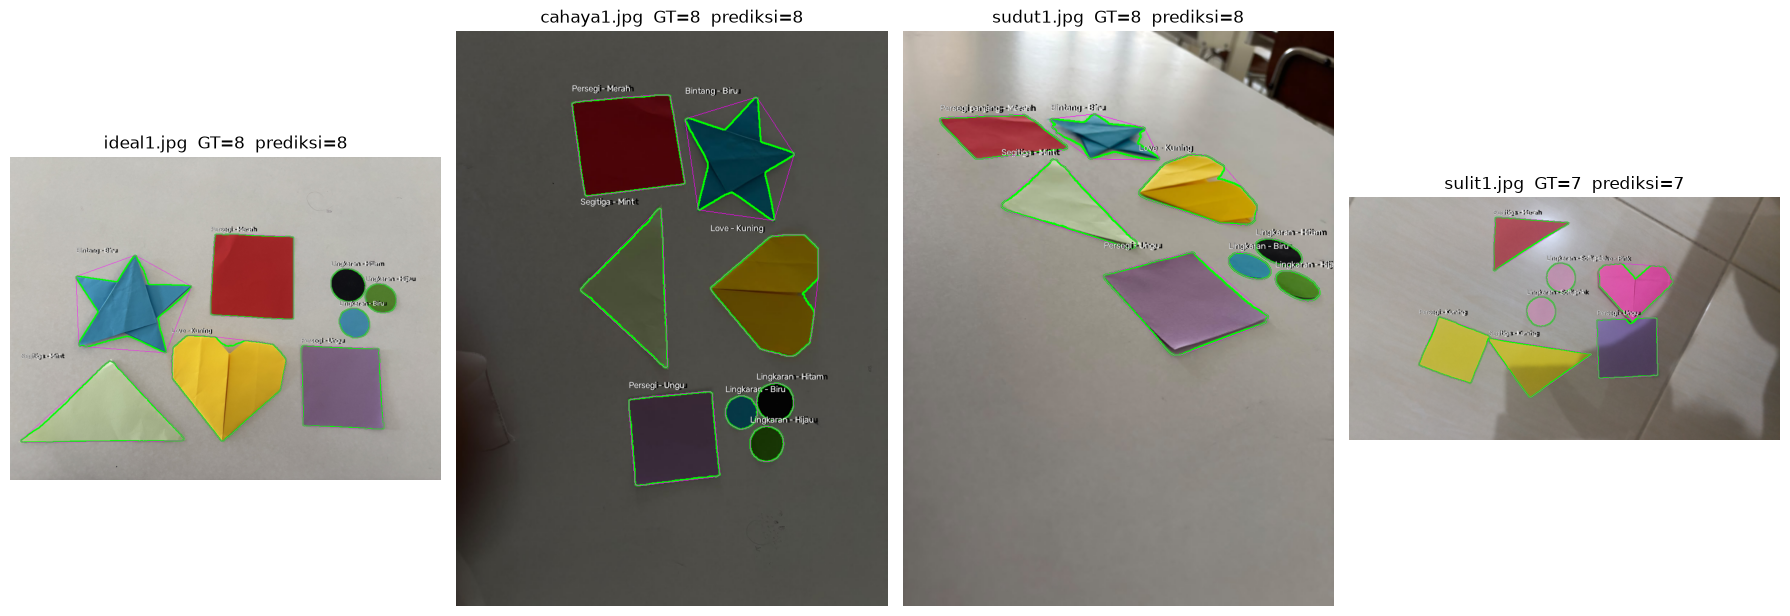

In [221]:
# Contoh hasil akhir 1 foto per kondisi
fig, axes = plt.subplots(1, 4, figsize=(18, 7))
for ax, k in zip(axes, KONDISI):
    h = next(h for h in HASIL if h["kondisi"] == k)
    img, a = CACHE[h["file"]]
    ax.imshow(cv2.cvtColor(gambar_hasil(img, a["objek"]), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{h['file']}  GT={h['n_gt']}  prediksi={h['n_pred']}")
    ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Eksperimen pembanding

Tiga perbandingan: **(A)** nilai epsilon `approxPolyDP` (sesuai soal), **(B)** `HoughCircles` vs pipeline kontur untuk lingkaran (sesuai soal),
dan dua perbandingan tambahan yang menjelaskan masalah awal: **(C)** mask `inRange` HSV vs mask selisih-latar, **(D)** klasifikasi warna `inRange` HSV vs Lab relatif latar.

### A. Pengaruh epsilon `approxPolyDP`

Epsilon dinyatakan sebagai pecahan dari keliling (`epsilon = e × arcLength`). Kontur yang sama (hasil segmentasi tetap) diklasifikasikan ulang
dengan satu nilai `e` untuk seluruh aturan. Baris "default" memakai 0,02 untuk membedakan banyak titik (lekukan love, kotak) dan 0,04 untuk segitiga.

   epsilon  akurasi bentuk   titik rata2 persegi   titik rata2 segitiga
      0.01           82.2%                   4.2                    3.5
      0.02           90.7%                   4.0                    3.0
      0.04           86.4%                   4.0                    3.0
      0.06           56.5%                   4.0                    3.0
      0.08           56.5%                   4.0                    3.0
   default           90.7%   (0,02 untuk jumlah titik halus + 0,04 untuk segitiga)


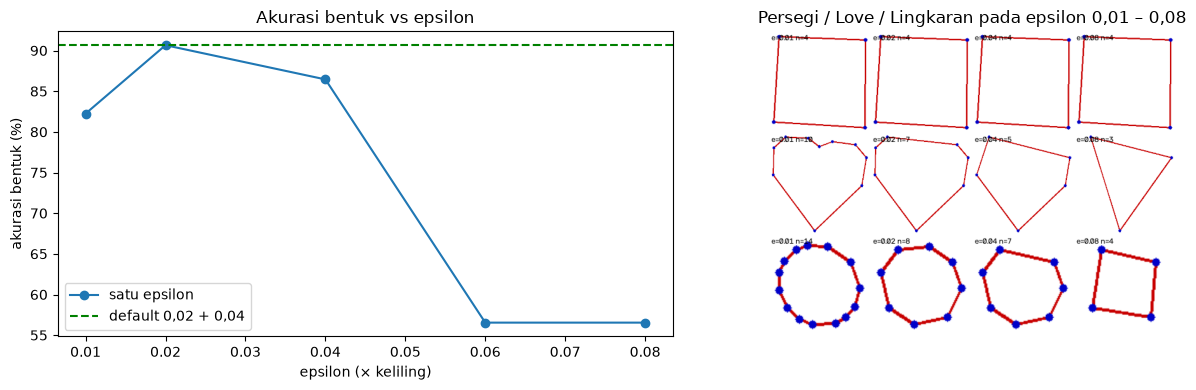

In [222]:
def akurasi_bentuk(eps_halus, eps_kasar):
    ok = pen = 0
    for h in HASIL:
        img, a = CACHE[h["file"]]
        objek = klasifikasi_objek(a["kontur"], a["lab"], a["latar"], eps_halus, eps_kasar)
        pred = [(o["bentuk"], o["warna"]) for o in objek]
        _, b, _ = cocokkan(pred, parse_keterangan(next(r for r in GT if r["file"] == h["file"])["keterangan"]))
        ok += b; pen += max(len(pred), h["n_gt"])
    return 100 * ok / pen

def rata_titik(bentuk_cari, eps):
    n = []
    for h in HASIL:
        for o in CACHE[h["file"]][1]["objek"]:
            if o["bentuk"] == bentuk_cari:
                n.append(len(cv2.approxPolyDP(o["kontur"], eps * o["fitur"]["keliling"], True)))
    return np.mean(n)

EPS = [0.01, 0.02, 0.04, 0.06, 0.08]
akurasi_eps = [akurasi_bentuk(e, e) for e in EPS]
default = akurasi_bentuk(0.02, 0.04)

print(f"{'epsilon':>10s}{'akurasi bentuk':>16s}{'titik rata2 persegi':>22s}{'titik rata2 segitiga':>23s}")
for e, a in zip(EPS, akurasi_eps):
    print(f"{e:10.2f}{a:15.1f}%{rata_titik('Persegi', e):22.1f}{rata_titik('Segitiga', e):23.1f}")
print(f"{'default':>10s}{default:15.1f}%   (0,02 untuk jumlah titik halus + 0,04 untuk segitiga)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(EPS, akurasi_eps, "o-", label="satu epsilon")
axes[0].axhline(default, color="g", ls="--", label="default 0,02 + 0,04")
axes[0].set_xlabel("epsilon (× keliling)"); axes[0].set_ylabel("akurasi bentuk (%)"); axes[0].legend(); axes[0].set_title("Akurasi bentuk vs epsilon")

# ilustrasi: kontur lingkaran, persegi, dan love pada beberapa epsilon
contoh = {}
for h in HASIL:
    for o in CACHE[h["file"]][1]["objek"]:
        contoh.setdefault(o["bentuk"], o["kontur"])
kanvas = []
for nama in ["Persegi", "Love", "Lingkaran"]:
    c = contoh[nama]; x, y, w, hh = cv2.boundingRect(c)
    baris = []
    for e in [0.01, 0.02, 0.04, 0.08]:
        im = np.full((hh + 20, w + 20, 3), 255, np.uint8)
        ap = cv2.approxPolyDP(c, e * cv2.arcLength(c, True), True) - [x - 10, y - 10]
        cv2.polylines(im, [ap], True, (0, 0, 200), 2)
        for p in ap[:, 0]:
            cv2.circle(im, tuple(int(v) for v in p), 4, (200, 0, 0), -1)
        im = cv2.resize(im, (160, 160))
        cv2.putText(im, f"e={e} n={len(ap)}", (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 1)
        baris.append(im)
    kanvas.append(np.hstack(baris))
axes[1].imshow(cv2.cvtColor(np.vstack(kanvas), cv2.COLOR_BGR2RGB)); axes[1].axis("off")
axes[1].set_title("Persegi / Love / Lingkaran pada epsilon 0,01 – 0,08")
plt.tight_layout(); plt.show()

**Analisis A.** Akurasi puncak ada pada epsilon 0,02 (90,7%), turun di 0,04 (86,4%) dan ambruk di ≥0,06 (56,5%).
- Epsilon **0,01** terlalu teliti: sisi yang sedikit bergelombang menghasilkan banyak titik, sehingga persegi dan segitiga sebagian terbaca sebagai *love* (pada percobaan ini *love* berlebih 21, persegi kurang 14, segitiga kurang 15).
- Epsilon **≥0,06** terlalu kasar: semua lingkaran (60 buah) hanya tersisa 4–5 titik dan terbaca sebagai persegi/persegi panjang, dan lekukan *love* hilang.
- Karena itu pipeline memakai **dua** epsilon: 0,04 untuk memastikan segitiga (3 titik) dan 0,02 untuk membedakan persegi (≤5 titik) dari *love*/lingkaran (≥6 titik).

### B. HoughCircles vs pipeline kontur untuk lingkaran

`HoughCircles` dijalankan pada citra gray yang di-median blur, tanpa segmentasi mask. Perbandingan dilakukan pada **jumlah lingkaran per foto**
(ground truth memuat jumlah lingkaran, bukan posisinya).

kondisi    lingkaran GT  kontur: tepat  kontur: MAE  Hough: tepat  Hough: MAE
ideal                23          10/10         0.00          7/10        0.60
cahaya                8            3/4         0.25           3/4        0.50
sudut                12            6/6         0.00           1/6        4.83
sulit                17            7/7         0.00           3/7        0.71
TOTAL                60          26/27         0.04         14/27        1.56


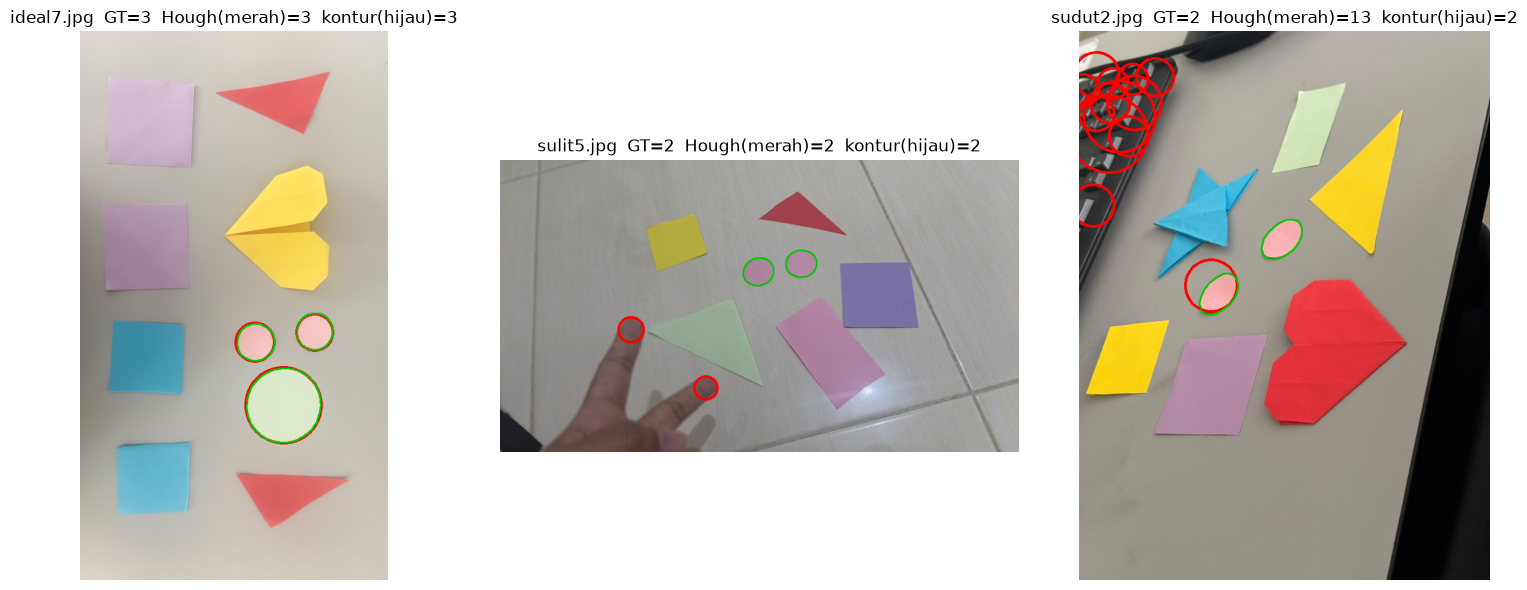

In [223]:
def hough_lingkaran(img):
    gray = cv2.medianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), 5)
    c = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1.2, minDist=30, param1=100, param2=30, minRadius=15, maxRadius=80)
    return (0 if c is None else c.shape[1]), c

rows = []
for h in HASIL:
    img, a = CACHE[h["file"]]
    n_gt = sum(1 for b, w in h["gt"] if b == "Lingkaran")
    n_kontur = sum(1 for o in a["objek"] if o["bentuk"] == "Lingkaran")
    n_hough, _ = hough_lingkaran(img)
    rows.append((h["file"], h["kondisi"], n_gt, n_kontur, n_hough))

print(f"{'kondisi':9s}{'lingkaran GT':>14s}{'kontur: tepat':>15s}{'kontur: MAE':>13s}{'Hough: tepat':>14s}{'Hough: MAE':>12s}")
for k in KONDISI + ["TOTAL"]:
    R = rows if k == "TOTAL" else [r for r in rows if r[1] == k]
    gt_ = np.array([r[2] for r in R]); kc = np.array([r[3] for r in R]); hg = np.array([r[4] for r in R])
    print(f"{k:9s}{gt_.sum():14d}{f'{(kc == gt_).sum()}/{len(R)}':>15s}{np.abs(kc - gt_).mean():13.2f}{f'{(hg == gt_).sum()}/{len(R)}':>14s}{np.abs(hg - gt_).mean():12.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, nama in zip(axes, ["ideal7.jpg", "sulit5.jpg", "sudut2.jpg"]):
    img, a = CACHE[nama]
    n, c = hough_lingkaran(img)
    vis = img.copy()
    if c is not None:
        for x, y, r in np.round(c[0]).astype(int):
            cv2.circle(vis, (x, y), r, (0, 0, 255), 3)
    for o in a["objek"]:
        if o["bentuk"] == "Lingkaran":
            cv2.drawContours(vis, [o["kontur"]], -1, (0, 200, 0), 2)
    gt_ = next(h for h in HASIL if h["file"] == nama)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{nama}  GT={sum(1 for b, w in gt_['gt'] if b == 'Lingkaran')}  Hough(merah)={n}  kontur(hijau)=" + str(sum(1 for o in a['objek'] if o['bentuk'] == 'Lingkaran')))
    ax.axis("off")
plt.tight_layout(); plt.show()

**Analisis B.** Pendekatan kontur menebak jumlah lingkaran dengan tepat pada 26 dari 27 foto (MAE 0,04), sedangkan `HoughCircles` tepat pada 14 dari 27 (MAE 1,56).
`HoughCircles` bekerja langsung pada tepi sehingga terganggu nat lantai, pola keyboard, dan lipatan kertas (lingkaran palsu), apalagi pada foto miring (`sudut`, MAE 4,83), dan lingkaran yang difoto miring berubah menjadi elips yang tidak cocok dengan model lingkaran Hough.
Parameter Hough (`param2`, radius) juga harus dituning per kondisi. Pendekatan kontur memakai mask yang sudah bersih dan kriteria solidity serta kecocokan elips sehingga lebih stabil.
Kekurangannya: kontur bergantung penuh pada kualitas mask, sedangkan Hough tidak butuh segmentasi.

### C. Mask `inRange` HSV vs mask selisih-latar

Pembanding adalah cara awal: `inRange` HSV (S ≥ 35, V ≥ 30), morfologi open/close, `findContours`, filter luas. Yang diukur hanya **jumlah objek**
terhadap ground truth, karena ini yang langsung dipengaruhi kualitas mask.

kondisi    HSV inRange: tepat    MAE   selisih-latar: tepat    MAE
ideal                    1/10   2.90                  10/10   0.00
cahaya                    1/4   3.50                    3/4   0.25
sudut                     1/6   1.00                    4/6   0.33
sulit                     0/7   2.57                    2/7   1.14
TOTAL                    3/27   2.48                  19/27   0.41


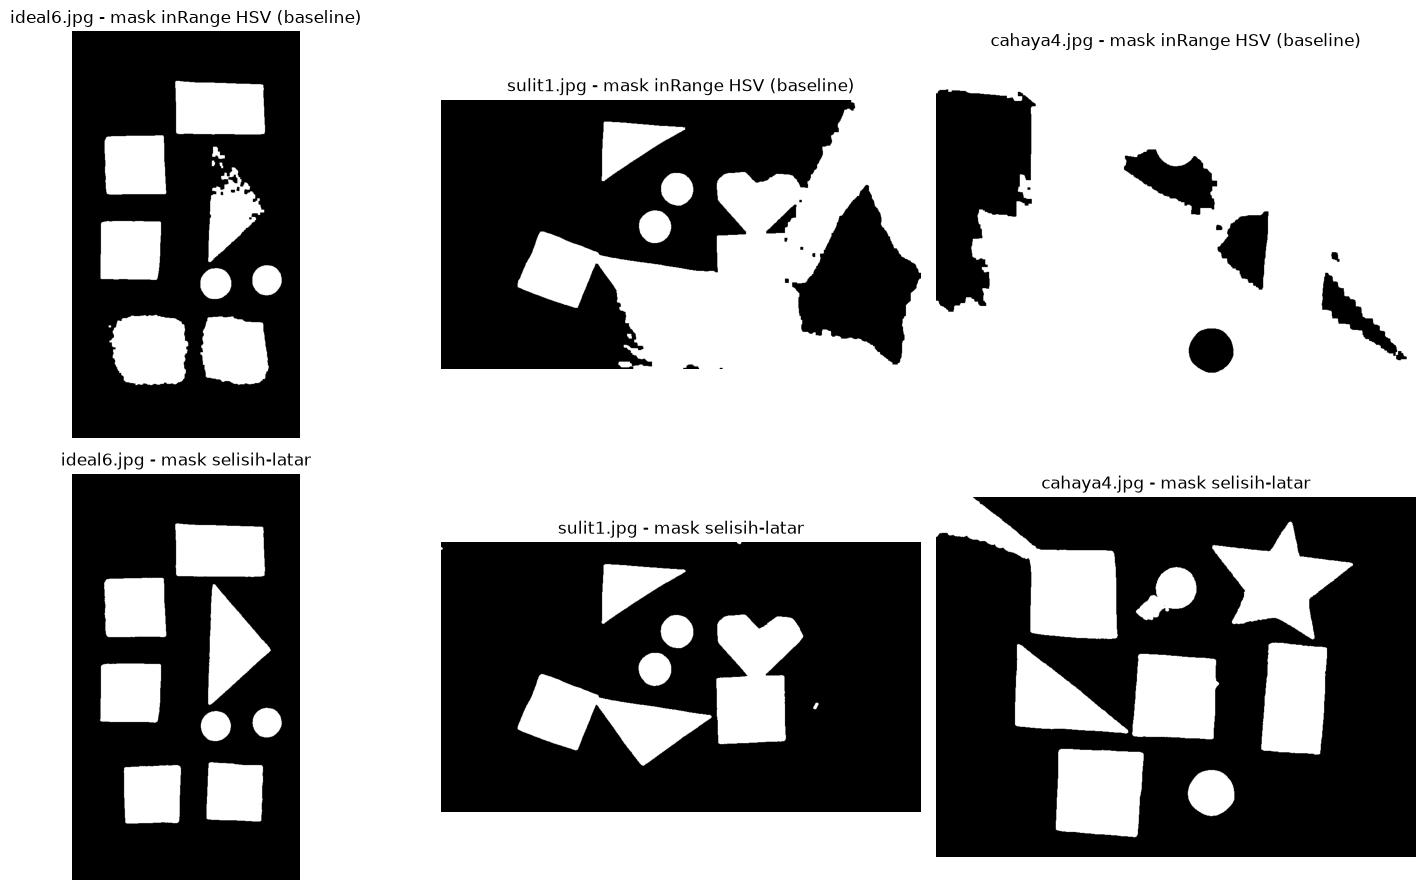

In [224]:
def mask_hsv_inrange(img):
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (5, 5), 0), cv2.COLOR_BGR2HSV)
    m = cv2.inRange(hsv, np.array([0, 35, 30]), np.array([179, 255, 255]))
    k = np.ones((5, 5), np.uint8)
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)
    return m

def hitung_hsv(img):
    m = mask_hsv_inrange(img)
    cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    total = m.size
    return sum(1 for c in cs if total * 0.0009 <= cv2.contourArea(c) <= total * 0.12)

print(f"{'kondisi':9s}{'HSV inRange: tepat':>20s}{'MAE':>7s}{'selisih-latar: tepat':>23s}{'MAE':>7s}")
for k in KONDISI + ["TOTAL"]:
    daftar = HASIL if k == "TOTAL" else [h for h in HASIL if h["kondisi"] == k]
    gt_ = np.array([h["n_gt"] for h in daftar])
    hs = np.array([hitung_hsv(CACHE[h["file"]][0]) for h in daftar])
    fn = np.array([h["n_pred"] for h in daftar])
    print(f"{k:9s}{f'{(hs == gt_).sum()}/{len(daftar)}':>20s}{np.abs(hs - gt_).mean():7.2f}{f'{(fn == gt_).sum()}/{len(daftar)}':>23s}{np.abs(fn - gt_).mean():7.2f}")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, nama in enumerate(["ideal6.jpg", "sulit1.jpg", "cahaya4.jpg"]):
    img, a = CACHE[nama]
    axes[0, j].imshow(mask_hsv_inrange(img), cmap="gray"); axes[0, j].set_title(f"{nama} - mask inRange HSV (baseline)")
    axes[1, j].imshow(a["mask"], cmap="gray"); axes[1, j].set_title(f"{nama} - mask selisih-latar")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

**Analisis C.** Mask `inRange` HSV hanya menghitung jumlah objek dengan tepat pada 3 dari 27 foto (MAE 2,48), sedangkan mask selisih-latar 19 dari 27 (MAE 0,41).
Pada foto ideal sekalipun `inRange` HSV kehilangan kertas pastel (pink muda, hijau muda) karena saturasinya mendekati latar, sementara pada foto sulit/cahaya latar berwarna dan pola lantai ikut masuk mask.
Catatan kejujuran: pembanding ini adalah cara awal *tanpa* estimasi latar, pemisahan objek menempel, dan filter tepi, sehingga sebagian selisihnya berasal dari tahap-tahap tambahan tersebut, bukan dari `inRange` saja.

### D. Klasifikasi warna: `inRange` HSV vs Lab relatif latar

Pada objek yang sama (hasil deteksi pipeline), warna ditentukan dengan dua cara: (1) rentang HSV tetap dengan `inRange` (warna dengan cakupan terbesar di dalam objek menang),
(2) sudut dan kekuatan warna (a,b) relatif terhadap latar lokal (pipeline utama).

In [225]:
RENTANG_HSV = {
    "Merah":     [((0, 100, 60), (6, 255, 255)), ((176, 100, 60), (179, 255, 255))],
    "Pink":      [((158, 100, 60), (175, 255, 255))],
    "Soft pink": [((159, 25, 150), (179, 99, 255)), ((0, 25, 150), (8, 99, 255))],
    "Ungu":      [((120, 20, 40), (158, 120, 255))],
    "Kuning":    [((18, 100, 60), (35, 255, 255))],
    "Hijau":     [((36, 85, 20), (85, 255, 200))],
    "Mint":      [((30, 10, 120), (60, 84, 255))],
    "Biru":      [((86, 100, 40), (130, 255, 255))],
    "Hitam":     [((0, 0, 0), (179, 110, 74))],
}

def warna_hsv_inrange(hsv, c):
    er = mask_dalam(hsv.shape, c)
    total = max((er > 0).sum(), 1)
    skor = {}
    for nama, daftar in RENTANG_HSV.items():
        m = np.zeros(er.shape, np.uint8)
        for bawah, atas in daftar:
            m |= cv2.inRange(hsv, np.array(bawah), np.array(atas))
        skor[nama] = ((m > 0) & (er > 0)).sum() / total
    return max(skor, key=skor.get)

ok_hsv = ok_lab = pen = 0
per_kondisi = {k: [0, 0, 0] for k in KONDISI}
for h in HASIL:
    img, a = CACHE[h["file"]]
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (5, 5), 0), cv2.COLOR_BGR2HSV)
    pred_hsv = [(o["bentuk"], warna_hsv_inrange(hsv, o["kontur"])) for o in a["objek"]]
    pred_lab = [(o["bentuk"], o["warna"]) for o in a["objek"]]
    gt_ = h["gt"]
    _, _, w_hsv = cocokkan(pred_hsv, gt_)
    _, _, w_lab = cocokkan(pred_lab, gt_)
    p = max(len(gt_), len(pred_lab))
    per_kondisi[h["kondisi"]][0] += w_hsv; per_kondisi[h["kondisi"]][1] += w_lab; per_kondisi[h["kondisi"]][2] += p
    ok_hsv += w_hsv; ok_lab += w_lab; pen += p

print(f"{'kondisi':9s}{'HSV inRange':>14s}{'Lab relatif latar':>20s}")
for k in KONDISI:
    s = per_kondisi[k]
    print(f"{k:9s}{100 * s[0] / s[2]:13.1f}%{100 * s[1] / s[2]:19.1f}%")
print(f"{'TOTAL':9s}{100 * ok_hsv / pen:13.1f}%{100 * ok_lab / pen:19.1f}%")

kondisi     HSV inRange   Lab relatif latar
ideal            100.0%              100.0%
cahaya            70.0%               90.0%
sudut             88.9%               93.3%
sulit             83.9%               85.7%
TOTAL             89.3%               93.5%


**Analisis D.** Pada objek yang sama, rentang HSV tetap mencapai 89,3% dan Lab relatif latar 93,5%, jadi selisihnya kecil di total. Bedanya terlihat pada foto `cahaya` (70,0% vs 90,0%),
karena lampu redup/kuning menggeser hue dan saturasi sehingga rentang tetap meleset, sedangkan warna yang dihitung relatif terhadap latar ikut "tergeser bersama".
Perlu diingat rentang HSV di atas disusun setelah melihat dataset ini, jadi nilainya cenderung optimistis untuk data baru.

## 7. Analisis kegagalan

Tiga foto dengan akurasi label terendah ditampilkan beserta objek yang terlewat (*missed*) dan objek berlebih (*extra*).

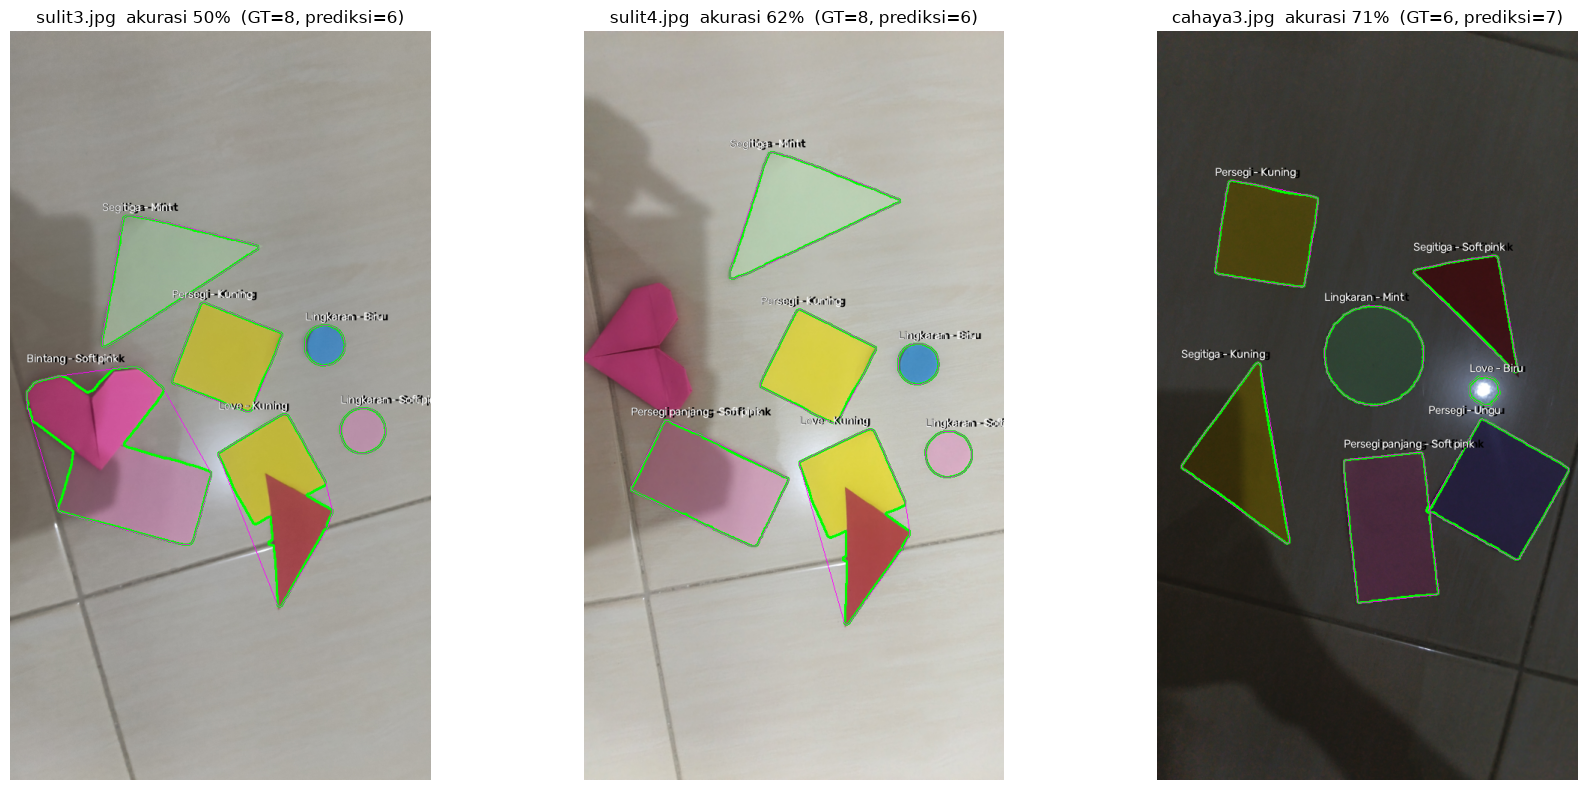

sulit3.jpg
   terlewat : {'Persegi panjang Soft pink': 1, 'Persegi Kuning': 1, 'Segitiga Merah': 1, 'Love Pink': 1}
   berlebih : {'Bintang Soft pink': 1, 'Love Kuning': 1}
sulit4.jpg
   terlewat : {'Persegi Kuning': 1, 'Segitiga Merah': 1, 'Love Pink': 1}
   berlebih : {'Love Kuning': 1}
cahaya3.jpg
   terlewat : {'Segitiga Merah': 1}
   berlebih : {'Segitiga Soft pink': 1, 'Love Biru': 1}


In [226]:
terburuk = sorted(HASIL, key=lambda h: h["lab_ok"] / h["penyebut"])[:3]
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, h in zip(axes, terburuk):
    img, a = CACHE[h["file"]]
    ax.imshow(cv2.cvtColor(gambar_hasil(img, a["objek"]), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{h['file']}  akurasi {100 * h['lab_ok'] / h['penyebut']:.0f}%  (GT={h['n_gt']}, prediksi={h['n_pred']})")
    ax.axis("off")
plt.tight_layout(); plt.show()

for h in terburuk:
    miss = Counter(h["gt"]) - Counter(h["pred"])
    extra = Counter(h["pred"]) - Counter(h["gt"])
    print(h["file"])
    print("   terlewat :", {f"{b} {w}": n for (b, w), n in miss.items()})
    print("   berlebih :", {f"{b} {w}": n for (b, w), n in extra.items()})

Penyebab kegagalan (berdasarkan gambar di atas):

1. **`sulit3.jpg` dan `sulit4.jpg` (objek bersentuhan).** Persegi kuning dan segitiga merah saling menempel sehingga menjadi satu komponen dan terbaca sebagai satu *love* kuning; pada `sulit3` hati pink dan persegi panjang pink juga menyatu (terbaca *bintang*). Watershed berbasis inti distance transform tidak memisahkannya karena sambungannya lebar dan warna kedua objek sama-sama menonjol dari latar. Selain itu hati pink di tepi kiri `sulit4` terpotong tepi foto dan berada di bayangan, sehingga dibuang oleh filter tepi.
2. **`cahaya3.jpg` (cahaya redup).** Segitiga merah tua di bawah cahaya redup hampir hitam: kroma kecil dan arah warnanya tidak stabil sehingga terbaca *soft pink*. Pantulan lampu membentuk bercak putih kecil dengan cincin kebiruan yang lolos filter dan terbaca *love biru*.
3. **Foto `sudut` (miring).** Persegi yang difoto sangat miring menjadi jajar genjang dengan rasio sisi yang bergeser sehingga terbaca *persegi panjang* (persegi merah di `sudut1`). Persegi kuning di `sudut4` dan `sudut5` terlewat atau salah bentuk karena terpotong/menempel tepi foto atau menyatu dengan objek lain. Beberapa objek palsu kecil (misalnya *segitiga biru* di `sudut4` dan `sudut6`) lolos filter; kemungkinan berasal dari tepi meja atau bayangan.
4. **Ambiguitas ground truth.** Lipatan origami "love" tertentu (kuning, pink) bentuknya mirip pesawat atau bintang. Pada `ideal10.jpg` bentuk pink yang di ground truth ditulis *love* terbaca *bintang* karena banyak cekungan.

Perbaikan yang mungkin: pemisahan objek berbasis warna (watershed pada gradien warna atau k-means pada a,b), ambang kroma adaptif untuk foto gelap, dan menolak blob dengan bagian tengah yang sangat terang (pantulan lampu).

## 8. Kesimpulan

- Pipeline memenuhi kriteria minimal: mengenali 6 bentuk (segitiga, persegi, persegi panjang, lingkaran, bintang, love) dan 9 warna (merah, kuning, hijau, biru, hitam, mint, ungu, pink, soft pink); persegi dan persegi panjang dibedakan lewat rasio sisi.
- Akurasi label total 88,8% pada 27 foto: ideal 98,8%, cahaya 86,7%, sudut 84,4%, sulit 78,6%. Bentuk 90,7% dan warna 93,5%.
- Sumber kesalahan awal ada pada **mask**. Mask `inRange` HSV dengan rentang tetap gagal untuk kertas pastel, latar berwarna, dan cahaya berubah. Menghitung selisih terhadap **latar lokal** (kroma di Lab) memperbaikinya: jumlah objek tepat pada 19/27 foto vs 3/27.
- Eksperimen: epsilon 0,02 (+0,04 untuk segitiga) terbaik untuk `approxPolyDP`, dan pendekatan kontur lebih stabil dibanding `HoughCircles` untuk lingkaran.
- Keterbatasan: objek yang saling menempel, pantulan lampu, objek yang terpotong tepi foto, dan warna sangat gelap. Parameter dan beberapa batas aturan disetel pada dataset ini sehingga akurasi pada data baru bisa lebih rendah.

## 9. Uji pada foto baru



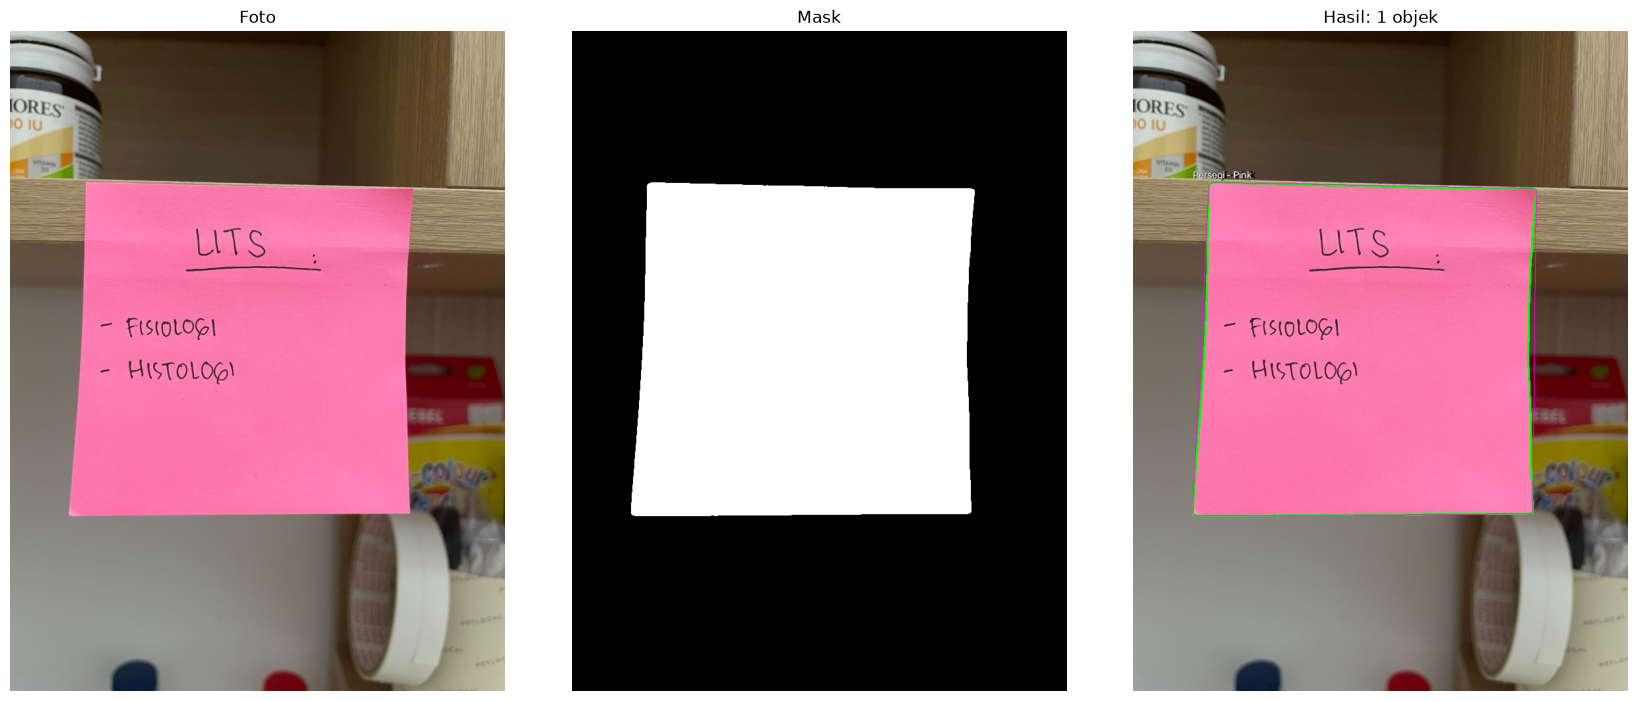

 1. Persegi - Pink


In [228]:
FOTO_BARU = "tes.jpeg"  

def demo(path):
    img = muat_citra(path)
    hasil = analisis_otomatis(img)
    fig, axes = plt.subplots(1, 3, figsize=(17, 7))
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0].set_title("Foto")
    axes[1].imshow(hasil["mask"], cmap="gray"); axes[1].set_title(f"Mask")
    axes[2].imshow(cv2.cvtColor(gambar_hasil(img, hasil["objek"]), cv2.COLOR_BGR2RGB))
    axes[2].set_title(f"Hasil: {len(hasil['objek'])} objek")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout(); plt.show()
    for i, o in enumerate(hasil["objek"], 1):
        print(f"{i:2d}. {o['bentuk']} - {o['warna']}")

demo(FOTO_BARU)